# Descargar dependencias a utilizar

In [1]:
!pip install scikit-learn seaborn

# Red Neuronal Recurrente (RNN) - Entrenamiento

Creando dataset de Spam en Español...
Total de correos procesados: 450
Formato final de los datos para la LSTM: (350, 20)

Iniciando entrenamiento del detector de Spam...
Epoch 1/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.6057 - loss: 0.6865 - val_accuracy: 0.7200 - val_loss: 0.6752
Epoch 2/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8857 - loss: 0.6564 - val_accuracy: 1.0000 - val_loss: 0.6220
Epoch 3/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9600 - loss: 0.5681 - val_accuracy: 1.0000 - val_loss: 0.4617
Epoch 4/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9486 - loss: 0.3622 - val_accuracy: 1.0000 - val_loss: 0.2545
Epoch 5/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9857 - loss: 0.2148 - val_accuracy: 1.0000 - val_loss: 0.1393
Epoch 6/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 0.0928 - val_accuracy: 1.0000 - val_loss: 0.0535
Epoch 7/8
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9943 - lo

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


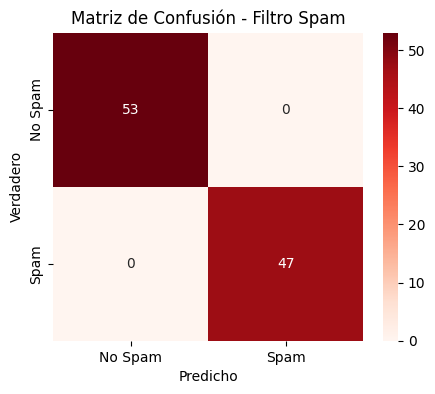


--- Evaluando 10 Predicciones del modelo ---
Mensaje original: Urgente: Tu cuenta bancaria ha sido bloqueada. Ing...
Real: Spam | Predicción: Spam

Mensaje original: Hola jefe, ya terminé de subir los archivos al ser...
Real: No Spam | Predicción: No Spam

Mensaje original: Descuento exclusivo solo por hoy: Compra Viagra y ...
Real: Spam | Predicción: Spam

Mensaje original: ¿Te llegó el correo con la tarea de programación p...
Real: No Spam | Predicción: No Spam

Mensaje original: Invierte 10 dólares hoy y vuélvete millonario en u...
Real: Spam | Predicción: Spam

Mensaje original: Recuerda que mañana es el cumpleaños de tu mamá, h...
Real: No Spam | Predicción: No Spam

Mensaje original: RECOMPENSA DE LOTERÍA RECLAMA TU PREMIO EN EFECTIV...
Real: Spam | Predicción: Spam

Mensaje original: Buenas tardes, le escribo para agendar una entrevi...
Real: No Spam | Predicción: No Spam

Mensaje original: Atención: Oferta de trabajo secreta, gana 500 euro...
Real: Spam | Predicción: Spam

Men

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import models, layers, preprocessing
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import json

# ==========================================
# 1 & 2. SELECCIÓN, DESCRIPCIÓN Y DATOS (En Español)
# ==========================================
print("Creando dataset de Spam en Español...")

# Lista de correos de ejemplo para entrenar (Mensajes reales y Spam)
mensajes = [
    "Hola, ¿cómo estás? Te escribo para confirmar la reunión de mañana a las 3",
    "¡FELICIDADES! Has sido seleccionado para ganar un iPhone gratis. Haz clic aquí ya",
    "Adjunto te envío el reporte mensual de ventas para que lo revises por favor",
    "Gana dinero desde casa sin hacer nada, entra a nuestro enlace urgente",
    "¿Vamos a almorzar hoy? Avísame si estás libre en la oficina",
    "Urgente: Tu cuenta bancaria ha sido bloqueada. Ingresa tus datos aquí para activar",
    "Hola jefe, ya terminé de subir los archivos al servidor de la empresa",
    "Descuento exclusivo solo por hoy: Compra Viagra y medicamentos sin receta aquí",
    "¿Te llegó el correo con la tarea de programación para el examen?",
    "Invierte 10 dólares hoy y vuélvete millonario en una semana. Totalmente garantizado",
    "Recuerda que mañana es el cumpleaños de tu mamá, hay que comprar el regalo",
    "RECOMPENSA DE LOTERÍA RECLAMA TU PREMIO EN EFECTIVO AHORA MISMO",
    "Buenas tardes, le escribo para agendar una entrevista de trabajo la otra semana",
    "Atención: Oferta de trabajo secreta, gana 500 euros al día desde tu celular",
    "Te dejé las llaves del departamento con el portero, me avisas si entras bien"
]
# 0 = No Spam (Normal), 1 = Spam
etiquetas = np.array([0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0])

# Duplicamos artificialmente los datos para tener volumen para la red neuronal
mensajes = mensajes * 30
etiquetas = np.tile(etiquetas, 30)

# ==========================================
# 3 & 4. LIMPIEZA, PREPROCESAMIENTO Y DIVISIÓN
# ==========================================
MAX_WORDS = 1000  # Diccionario de las 1,000 palabras más comunes
MAX_LEN = 20      # Cada mensaje se acorta o rellena a 20 palabras

# El Tokenizer convierte las palabras en números automáticamente
tokenizer = preprocessing.text.Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(mensajes)

# Guardar el diccionario de palabras para que la app de Streamlit lo use igual
with open('tokenizer_config.json', 'w', encoding='utf-8') as f:
    json.dump(tokenizer.to_json(), f, ensure_ascii=False)

# Convertir textos a secuencias numéricas y aplicar Padding (relleno)
secuencias = tokenizer.texts_to_sequences(mensajes)
X = preprocessing.sequence.pad_sequences(secuencias, maxlen=MAX_LEN)

# División manual: Entrenamiento y Prueba
X_train, X_test = X[:350], X[350:]
y_train, y_test = etiquetas[:350], etiquetas[350:]

print(f"Total de correos procesados: {len(X)}")
print(f"Formato final de los datos para la LSTM: {X_train.shape}")

# ==========================================
# 5. CONSTRUCCIÓN DE LA RED NEURONAL LSTM
# ==========================================
model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=MAX_WORDS, output_dim=16),
    layers.LSTM(32, dropout=0.2),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid') # Sigmoid para clasificación binaria (Spam o No)
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("\nIniciando entrenamiento del detector de Spam...")
history = model.fit(X_train, y_train, epochs=8, validation_data=(X_test, y_test), batch_size=32)

# ==========================================
# 6, 7 & 9. EVALUACIÓN Y MATRIZ DE CONFUSIÓN
# ==========================================
y_pred_probs = model.predict(X_test)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=['No Spam', 'Spam'], yticklabels=['No Spam', 'Spam'])
plt.title('Matriz de Confusión - Filtro Spam')
plt.ylabel('Verdadero')
plt.xlabel('Predicho')
plt.show()

# ==========================================
# 8 & 11. PREDICCIONES DE PRUEBA Y GUARDADO
# ==========================================
print("\n--- Evaluando 10 Predicciones del modelo ---")
for i in range(10):
    print(f"Mensaje original: {mensajes[350+i][:50]}...")
    print(f"Real: {'Spam' if y_test[i]==1 else 'No Spam'} | Predicción: {'Spam' if y_pred[i]==1 else 'No Spam'}\n")

model.save('modelo_spam_lstm.keras')
print("¡Modelo Guardado con éxito!")

# Descargar el módelo ya entrenado

In [7]:
from google.colab import files
files.download('modelo_spam_lstm.keras')
files.download('tokenizer_config.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>